# Experiments 3,4,5
## Date: 19-11-2026

#  3.Exploratory Data Analysis and Graphical Presentation

Student Performance: Exploratory Data Analysis

First 5 records:
 roll_no gender department grade  attendance  study_hours  marks
       1 Female        CSE     C          60          4.1     79
       2   Male        ECE     D          69          7.1    100
       3 Female        ECE     A          94          3.7     85
       4   Male        ECE     C          65          1.0     60
       5 Female        ECE     B          81          2.0     56

Classification of attributes:
  roll_no      : Nominal (identifier)
  gender       : Qualitative - Nominal
  department   : Qualitative - Nominal
  grade        : Qualitative - Ordinal
  attendance   : Quantitative - Discrete
  study_hours  : Quantitative - Continuous
  marks        : Quantitative - Discrete

Summary statistics:
       attendance  study_hours   marks
count       60.00        60.00   60.00
mean        79.53         4.11   76.57
std         11.29         1.91   12.98
min         60.00         1.00   51.00
25%         70.50 

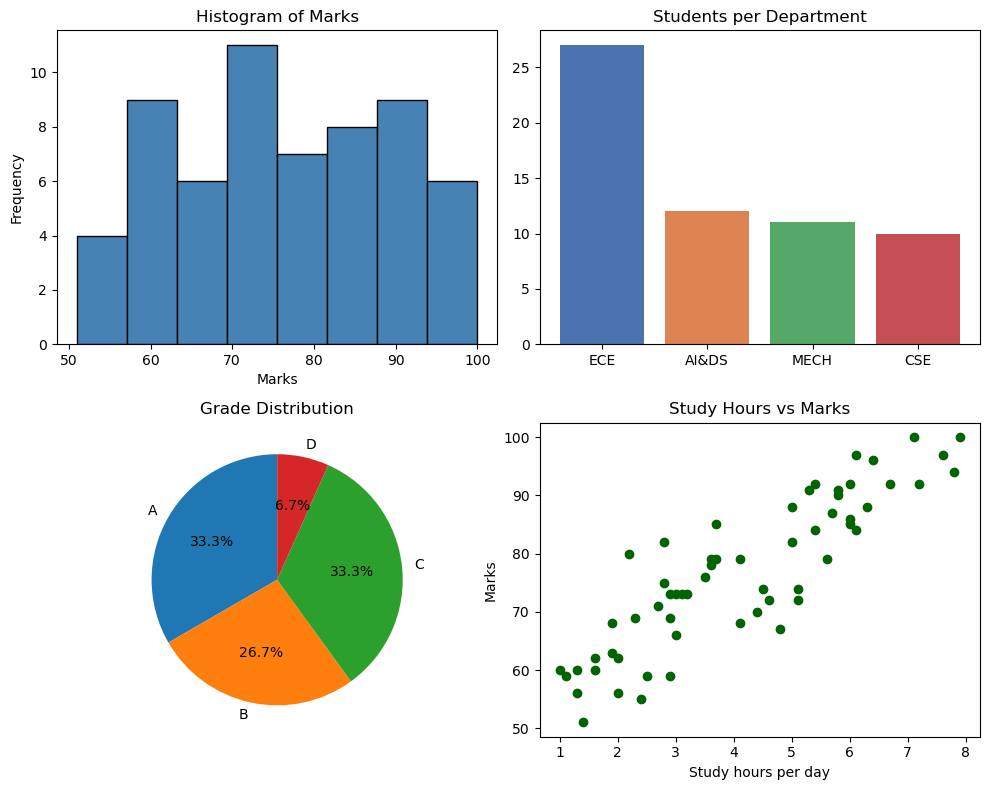


Plot saved as exp03_eda.png


In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
  
np.random.seed(7) 
n = 60 
students = pd.DataFrame( 
    { 
        "roll_no": range(1, n + 1), 
        "gender": np.random.choice(["Male", "Female"], n), 
        "department": np.random.choice( 
            ["CSE", "ECE", "MECH", "AI&DS"], n, p=[0.3, 0.25, 0.2, 0.25] 
        ), 
        "grade": np.random.choice( 
            ["A", "B", "C", "D"], n, p=[0.25, 0.4, 0.25, 0.1] 
        ), 
        "attendance": np.random.randint(60, 100, n), 
        "study_hours": np.round(np.random.uniform(1, 8, n), 1), 
    } 
) 
students["marks"] = np.clip( 
    ( 
        35 
        + 6 * students["study_hours"] 
        + 0.2 * students["attendance"] 
        + np.random.normal(0, 6, n) 
    ).round(), 
    0, 
    100, 
).astype(int) 
  
print("Student Performance: Exploratory Data Analysis") 
print("=" * 50) 
print("\nFirst 5 records:") 
print(students.head().to_string(index=False)) 
  
# ---------- Classification of data ---------- 
data_types = { 
    "roll_no": "Nominal (identifier)", 
    "gender": "Qualitative - Nominal", 
    "department": "Qualitative - Nominal", 
    "grade": "Qualitative - Ordinal", 
    "attendance": "Quantitative - Discrete", 
    "study_hours": "Quantitative - Continuous", 
    "marks": "Quantitative - Discrete", 
} 
print("\nClassification of attributes:") 
for col, t in data_types.items(): 
    print(f"  {col:<12} : {t}") 
  
# ---------- Descriptive statistics ---------- 
num = students[["attendance", "study_hours", "marks"]] 
print("\nSummary statistics:") 
print(num.describe().round(2).to_string()) 
print("\nMedian :", num.median().to_dict()) 
print("Mode of grade :", students["grade"].mode()[0]) 
print("Skewness of marks :", round(students["marks"].skew(), 3)) 
  
print("\nFrequency table - department:") 
print(students["department"].value_counts().to_string()) 
print("\nCross table - department vs grade:") 
print(pd.crosstab(students["department"], students["grade"]).to_string()) 
print("\nCorrelation matrix:") 
print(num.corr().round(3).to_string()) 
  
# ---------- Graphical presentation ---------- 
fig, ax = plt.subplots(2, 2, figsize=(10, 8)) 
ax[0, 0].hist(students["marks"], bins=8, color="steelblue", edgecolor="black") 
ax[0, 0].set_title("Histogram of Marks") 
ax[0, 0].set_xlabel("Marks") 
ax[0, 0].set_ylabel("Frequency") 
  
dept = students["department"].value_counts() 
ax[0, 1].bar( 
    dept.index, dept.values, color=["#4c72b0", "#dd8452", "#55a868", "#c44e52"] 
) 
ax[0, 1].set_title("Students per Department") 
  
grade = students["grade"].value_counts().sort_index() 
ax[1, 0].pie(grade.values, labels=grade.index, autopct="%1.1f%%", startangle=90) 
ax[1, 0].set_title("Grade Distribution") 
  
ax[1, 1].scatter(students["study_hours"], students["marks"], c="darkgreen") 
ax[1, 1].set_title("Study Hours vs Marks") 
ax[1, 1].set_xlabel("Study hours per day") 
ax[1, 1].set_ylabel("Marks") 
  
plt.tight_layout() 
plt.savefig("exp03_eda.png", dpi=150) 
plt.show() 
print("\nPlot saved as exp03_eda.png") 

# 4.Data Cleaning and Sampling for Modeling and Validation 

In [2]:
import numpy as np 
import pandas as pd 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler 
  
np.random.seed(42) 
n = 200 
df = pd.DataFrame( 
    { 
        "customer_id": range(1001, 1001 + n), 
        "age": np.random.randint(18, 70, n).astype(float), 
        "income": np.random.normal(45000, 12000, n).round(), 
        "city": np.random.choice( 
            ["Chennai", "chennai ", "Madurai", "Coimbatore"], n 
        ), 
        "purchases": np.random.poisson(6, n).astype(float), 
        "churn": np.random.choice(["Yes", "No"], n, p=[0.3, 0.7]), 
    } 
) 
# Inject typical data-quality problems 
df.loc[np.random.choice(n, 15, replace=False), "age"] = np.nan 
df.loc[np.random.choice(n, 10, replace=False), "income"] = np.nan 
df.loc[[5, 50, 120], "income"] = [450000, 520000, -3000]  # outliers / invalid 
df = pd.concat( 
    [df, df.iloc[[10, 20, 30, 40, 50]]], ignore_index=True 
)  # duplicates 
  
print("Customer Data: Cleaning and Sampling for Modeling") 
print("=" * 50) 
print("Raw shape:", df.shape) 
  
# ---------- 1. Missing values ---------- 
print("\n[1] Missing values per column:") 
print(df.isnull().sum().to_string()) 
  
# ---------- 2. Duplicates ---------- 
dups = df.duplicated().sum() 
df = df.drop_duplicates() 
print(f"\n[2] Duplicate rows removed: {dups}  -> shape {df.shape}") 
  
# ---------- 3. Inconsistent categories ---------- 
print("\n[3] City values before:", sorted(df["city"].unique())) 
df["city"] = df["city"].str.strip().str.title() 
print("    City values after :", sorted(df["city"].unique())) 
  
# ---------- 4. Invalid values and outliers (IQR rule) ---------- 
df.loc[df["income"] < 0, "income"] = np.nan 
q1, q3 = df["income"].quantile([0.25, 0.75]) 
iqr = q3 - q1 
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr 
outliers = df[(df["income"] < low) | (df["income"] > high)] 
print(f"\n[4] Income IQR bounds: {low:.0f} to {high:.0f}") 
print("    Outliers found:", len(outliers)) 
print(outliers[["customer_id", "income"]].to_string(index=False)) 
df["income"] = df["income"].clip(low, high) 
  
# ---------- 5. Imputation ---------- 
df["age"] = df["age"].fillna(df["age"].median()) 
df["income"] = df["income"].fillna(df["income"].mean()).round() 
print("\n[5] Missing values after imputation:", int(df.isnull().sum().sum())) 
  
# ---------- 6. Encoding and scaling ---------- 
df["churn"] = df["churn"].map({"No": 0, "Yes": 1}) 
df = pd.get_dummies(df, columns=["city"], drop_first=True, dtype=int) 
scaler = StandardScaler() 
df[["age", "income", "purchases"]] = scaler.fit_transform( 
    df[["age", "income", "purchases"]] 
) 
print("\n[6] Cleaned and transformed data (first 5 rows):") 
print(df.head().round(3).to_string(index=False)) 
  
# ---------- 7. Sampling ---------- 
X = df.drop(columns=["customer_id", "churn"]) 
y = df["churn"] 
simple = df.sample(frac=0.2, random_state=1) 
print( 
    "\n[7] Simple random sample (20%):", 
    len(simple), 
    "rows, churn rate =", 
    round(simple["churn"].mean(), 3), 
) 
  
X_train, X_temp, y_train, y_temp = train_test_split( 
    X, y, test_size=0.3, stratify=y, random_state=1 
) 
X_val, X_test, y_val, y_test = train_test_split( 
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=1 
) 
print("\nStratified Train / Validation / Test split (70/15/15):") 
for name, part in [ 
    ("Overall", y), 
    ("Train", y_train), 
    ("Validation", y_val), 
    ("Test", y_test), 
]: 
    print(f"  {name:<11} rows = {len(part):>3}   churn rate = {part.mean():.3f}") 

Customer Data: Cleaning and Sampling for Modeling
Raw shape: (205, 6)

[1] Missing values per column:
customer_id     0
age            16
income         10
city            0
purchases       0
churn           0

[2] Duplicate rows removed: 5  -> shape (200, 6)

[3] City values before: ['Chennai', 'Coimbatore', 'Madurai', 'chennai ']
    City values after : ['Chennai', 'Coimbatore', 'Madurai']

[4] Income IQR bounds: 11224 to 79240
    Outliers found: 4
 customer_id   income
        1006 450000.0
        1051 520000.0
        1073  10447.0
        1171  83244.0

[5] Missing values after imputation: 0

[6] Cleaned and transformed data (first 5 rows):
 customer_id    age  income  purchases  churn  city_Coimbatore  city_Madurai
        1001  0.877   0.095      0.760      0                0             1
        1002  1.785  -1.211     -0.418      0                0             0
        1003  0.179   1.821     -1.203      0                1             0
        1004 -0.799  -0.171     -0.4

# 5.Linear Regression for House Price Prediction

House Price Prediction using Linear Regression
 area_sqft  bedrooms  age_years  distance_km  price_lakhs
      1789         1         22         22.5        64.07
      1027         1         29          2.4        41.98
      1844         3         10         10.7        83.57
      1680         3          7          4.1        92.16
      2509         3         28          3.1       120.57

Correlation with price:
area_sqft      0.923
bedrooms       0.060
age_years     -0.130
distance_km   -0.223

Simple Linear Regression: price = b0 + b1 * area
  b0 (intercept) = 4.4216
  b1 (slope)     = 0.0427
  R^2 on test    = 0.8528

Multiple Linear Regression coefficients:
  Intercept      19.5214
  area_sqft       0.0444
  bedrooms        3.0285
  age_years      -0.6860
  distance_km    -1.1889

Model evaluation on test set:
  MAE  = 4.3166
  MSE  = 31.6882
  RMSE = 5.6292
  R^2  = 0.9709

Predicted price for 1800 sqft, 3 BHK, 5 yrs old, 8 km away: 95.63 lakhs


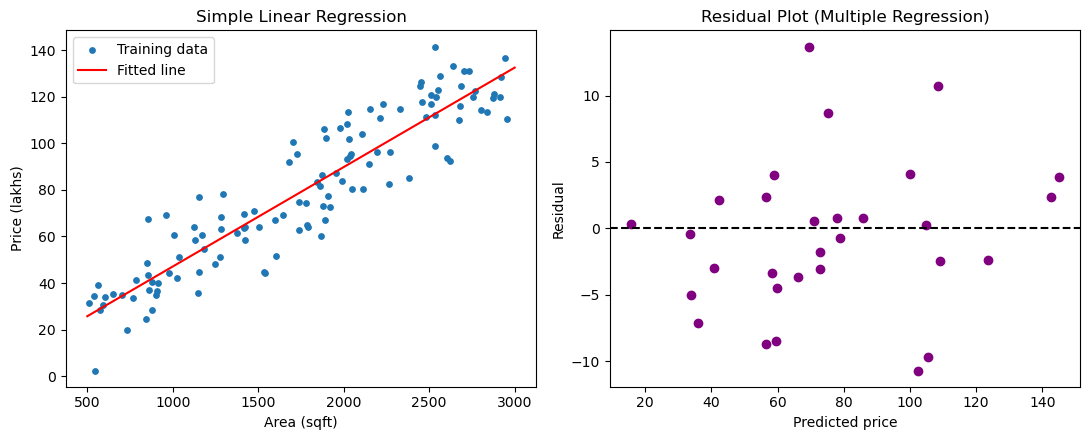

In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression 
from sklearn.model_selection import train_test_split 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
  
np.random.seed(10) 
n = 150 
area = np.random.randint(500, 3000, n) 
bedrooms = np.random.randint(1, 5, n) 
age = np.random.randint(0, 30, n) 
distance = np.round(np.random.uniform(1, 25, n), 1) 
price = ( 
    15 
    + 0.045 * area 
    + 4 * bedrooms 
    - 0.6 * age 
    - 1.2 * distance 
    + np.random.normal(0, 6, n) 
)  # price in lakhs 
houses = pd.DataFrame( 
    { 
        "area_sqft": area, 
        "bedrooms": bedrooms, 
        "age_years": age, 
        "distance_km": distance, 
        "price_lakhs": price.round(2), 
    } 
) 
  
print("House Price Prediction using Linear Regression") 
print("=" * 50) 
print(houses.head().to_string(index=False)) 
print("\nCorrelation with price:") 
print(houses.corr()["price_lakhs"].drop("price_lakhs").round(3).to_string()) 
  
X = houses.drop(columns="price_lakhs") 
y = houses["price_lakhs"] 
X_train, X_test, y_train, y_test = train_test_split( 
    X, y, test_size=0.2, random_state=1 
) 
  
# ---------- Simple linear regression (area only) ---------- 
simple = LinearRegression().fit(X_train[["area_sqft"]], y_train) 
print("\nSimple Linear Regression: price = b0 + b1 * area") 
print(f"  b0 (intercept) = {simple.intercept_:.4f}") 
print(f"  b1 (slope)     = {simple.coef_[0]:.4f}") 
print( 
    f"  R^2 on test    = {r2_score(y_test, simple.predict(X_test[['area_sqft']])):.4f}" 
) 
  
# ---------- Multiple linear regression ---------- 
model = LinearRegression().fit(X_train, y_train) 
print("\nMultiple Linear Regression coefficients:") 
print(f"  {'Intercept':<12} {model.intercept_:>9.4f}") 
for name, c in zip(X.columns, model.coef_): 
    print(f"  {name:<12} {c:>9.4f}") 
  
pred = model.predict(X_test) 
mse = mean_squared_error(y_test, pred) 
print("\nModel evaluation on test set:") 
print(f"  MAE  = {mean_absolute_error(y_test, pred):.4f}") 
print(f"  MSE  = {mse:.4f}") 
print(f"  RMSE = {np.sqrt(mse):.4f}") 
print(f"  R^2  = {r2_score(y_test, pred):.4f}") 
  
new_house = pd.DataFrame([[1800, 3, 5, 8.0]], columns=X.columns) 
print( 
    "\nPredicted price for 1800 sqft, 3 BHK, 5 yrs old, 8 km away:", 
    f"{model.predict(new_house)[0]:.2f} lakhs", 
) 
  
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5)) 
xs = np.linspace(500, 3000, 100).reshape(-1, 1) 
ax[0].scatter(X_train["area_sqft"], y_train, s=15, label="Training data") 
ax[0].plot( 
    xs, 
    simple.predict(pd.DataFrame(xs, columns=["area_sqft"])), 
    color="red", 
    label="Fitted line", 
) 
ax[0].set_xlabel("Area (sqft)") 
ax[0].set_ylabel("Price (lakhs)") 
ax[0].set_title("Simple Linear Regression") 
ax[0].legend() 
ax[1].scatter(pred, y_test - pred, color="purple") 
ax[1].axhline(0, color="black", linestyle="--") 
ax[1].set_xlabel("Predicted price") 
ax[1].set_ylabel("Residual") 
ax[1].set_title("Residual Plot (Multiple Regression)") 
plt.tight_layout() 
plt.savefig("exp05_regression.png", dpi=150) 
plt.show() 